
### **Notebook Structure**

In the first part of the notebook, we define all the functions required to perform the task. Next, we define a `main` function that implements the entire pipeline for detecting multiple instances given a single model and a single scene. Finally, we include the code that runs the detection on all possible model-scene combinations available in the dataset.

### **Pipeline Used**

Our pipeline starts by detecting the first instance of the book (if present) through feature matching, using SIFT for keypoint extraction, descriptor matching, and homography estimation.

Once the first occurrence is found, we use it as a template to perform template matching on the scene, aiming to detect any additional instances of the same book.

We adopted this approach because, in the given dataset, once the first instance is identified, the other occurrences of the book tend to appear with very similar angles, scales, and lighting conditions.

To make the detection more robust to slight variations in scale or rotation, we repeat the template matching by applying small rotations and rescalings to the scene.

Finally, to validate the matches obtained through template matching, we also check that there is a sufficient number of keypoint correspondences between the template and the matched region in the scene.

Below we describe in detail the steps of our pipeline for multiple instance detection.

#### **First Instance**

1. **Keypoint Extraction**: We use SIFT to extract keypoints from both the scene image and the model image.

2. **Descriptors Matching**: We perform descriptor matching using a brute-force approach, applying Lowe’s ratio test to select the good matches. We also experimented with FLANN to speed up this phase, but the gain in execution time was not significant. Therefore, in our proposed pipeline we use brute-force matching, which is exact and reproducible.

3. **Homography Estimation**: If the number of good matches is sufficient, we estimate the homography using RANSAC.

4. **Projection and Bounding Box Drawing**: Using the estimated homography, we project the four corners of the model onto the scene and draw the corresponding bounding box.


#### **Second and Subsequent Instances**

5. **Template Extraction for Template Matching**: We use the content of the bounding box found in step 4 as a new template for detecting further occurrences. This choice is motivated by two main observations:  
   - In the dataset, all instances beyond the first one have a very similar visual appearance;  
   - The new template has the same spatial dimensions as the other instances in the scene.  

   We are aware that template matching works reliably only in controlled environments, and after a careful analysis of the dataset, we considered our case to meet these conditions.

6. **Template Matching Execution**: We apply template matching with a version robust to small variations in scale (±5%) and rotation (±6°).  
   The metric used to evaluate the match quality is the Normalized Sum of Squared Differences (SSD).

7. **Hysteresis Thresholding**: Inspired by Canny's approach, we define two thresholds:  
   - A **low threshold**, below which a match is accepted automatically;  
   - A **high threshold**, above which a match is automatically rejected;  
   - If the SSD falls between the two thresholds, we perform an additional check: we recompute the keypoints and descriptors of the matched region and verify that it contains a sufficient number of good matches compared to the template extracted in step 5.

8. **Iteration**: We repeat steps 6 and 7 until a match is found with an SSD above the high threshold, which is rejected and causes the process to stop.



**Additional Notes**

- All steps in the pipeline operate on **grayscale images**.
- Every time a new instance is detected, the corresponding region is masked with a black patch, to avoid interference with subsequent detections.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def detect_and_describe_sift(image, sift_params=(0.04, 10, 1.6, 3, 0)):
    """
    Detect keypoints and compute descriptors using SIFT.

    Args:
        image (np.ndarray): Input image in grayscale.
        sift_params (tuple): Parameters for SIFT:
            contrast_threshold (float): Threshold for filtering weak keypoints.
            edge_threshold (int): Threshold for filtering edge-like keypoints.
            sigma (float): Gaussian smoothing parameter.
            nOctaveLayers (int): Number of layers in each octave.
            nfeatures (int): Max number of features to retain (0 = no limit).

    Returns:
        Tuple(List[cv2.KeyPoint], np.ndarray): 
            - List of detected keypoints.
            - Descriptors for the keypoints.
    """
    contrast_threshold, edge_threshold, sigma, nOctaveLayers, nfeatures = sift_params
    
    sift = cv2.SIFT_create(
        contrastThreshold=contrast_threshold,
        edgeThreshold=edge_threshold,
        sigma=sigma,
        nOctaveLayers=nOctaveLayers,
        nfeatures=nfeatures
    )

    kp, des = sift.detectAndCompute(image, None)

    return kp, des

In [3]:
def kp_matching(des1, des2, lowe_ratio=0.75, FLANN=False):
    """
    Match keypoints between two sets of descriptors using either FLANN or BFMatcher.
    Args:
        des1 (np.ndarray): Descriptors from the first image.
        des2 (np.ndarray): Descriptors from the second image.
        lowe_ratio (float): Ratio for Lowe's ratio test.
        FLANN (bool): Whether to use FLANN-based matcher or BFMatcher.
    Returns:
        List(cv2.DMatch): List of good matches after applying Lowe's ratio test.
    """

    if len(des1) <= 1 or len(des2) <= 1: # Need at least 2 descriptors for KNN
        return [], []

    if FLANN:
        index_params = dict(algorithm=1, trees=5)  # FLANN_INDEX_KDTREE
        search_params = dict(checks=50)
        flann = cv2.FlannBasedMatcher(index_params, search_params)
        matches = flann.knnMatch(des1, des2, k=2) # KNN matching to take the two best matches of each descriptor

    else:
        bf = cv2.BFMatcher(normType=cv2.NORM_L2)
        matches = bf.knnMatch(des1, des2, k=2) # KNN matching to take the two best matches of each descriptor

    if matches is None or len(matches) == 0:
        return [], []

    # Apply Lowe's ratio test to filter matches
    good_matches = []
    for m, n in matches:
        if m.distance < lowe_ratio * n.distance:
            good_matches.append(m)

    return good_matches

In [4]:
def find_model_in_scene(kp_model, kp_scene, min_match_count, good_matches, ransacReprojThreshold=5.0):
    """
    Find the homography between model keypoints and scene keypoints using RANSAC.
    Args:
        kp_model (List[cv2.KeyPoint]): Keypoints from the model image.
        kp_scene (List[cv2.KeyPoint]): Keypoints from the scene image.
        min_match_count (int): Minimum number of matches required to compute homography.
        good_matches (List[cv2.DMatch]): List of good matches after applying keypoint matching.
        ransacReprojThreshold (float): RANSAC reprojection threshold.
    Returns:
        Tuple(np.ndarray, np.ndarray):
            - Homography matrix if enough matches are found, otherwise None.
            - Mask indicating inliers from RANSAC.
    """

    if len(good_matches) < min_match_count:
        return None, None

    src_pts = np.float32([kp_model[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
    dst_pts = np.float32([kp_scene[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)

    M, mask = cv2.findHomography(src_pts, dst_pts, method=cv2.RANSAC, ransacReprojThreshold=ransacReprojThreshold)

    return M, mask

In [5]:
def order_points(pts):
        '''
        Returns corners in the order: top-left, top-right, bottom-right, bottom-left
        Args:
            pts (np.ndarray): Array containing four points.
        Returns:
            np.ndarray: Ordered corners in the shape (4, 2).
        '''
        pts = pts.reshape(-1, 2)
        rect = np.zeros((4, 2), dtype="float32")
        s = pts.sum(axis=1)
        rect[0] = pts[np.argmin(s)]      # Top-left
        rect[2] = pts[np.argmax(s)]      # Bottom-right

        diff = np.diff(pts, axis=1)
        rect[1] = pts[np.argmin(diff)]   # Top-right
        rect[3] = pts[np.argmax(diff)]   # Bottom-left
        return rect

In [6]:
def project_corners(M, img_model):
    """
    Project the corners of the model image into the scene using the homography matrix.
    Args:
        M (np.ndarray): Homography matrix.
        img_model (np.ndarray): Model image.
    Returns:
        np.ndarray: Projected corners in the scene.
    """
    
    h, w = img_model.shape[:2]

    # pts in the order of top-left, top-right, bottom-right, bottom-left
    pts = np.float32([[0, 0],[w-1, 0], [w-1, h-1], [0, h-1]]).reshape(-1, 1, 2) 

    dst = cv2.perspectiveTransform(pts, M)

    corners = order_points(dst)  # Order the corners

    corners = np.int32(corners)

    return corners

In [7]:
def draw_bounding_box(image, corners, color=(255, 0, 0)):
    """
    Draw a bounding box on the image using the given corners.
    """

    cv2.polylines(image, [corners], isClosed=True, color=color, thickness=3, lineType=cv2.LINE_AA)


In [8]:
def remove_object_from_scene(img_scene, corners, shrink_ratio=0.65):
    """ 
    Masks with a black rectangle the detected object in the scene image. The rectangle is 
    shrunk by a given ratio to avoid cutting objects near the detected one. Shrinking is done
    along the shorter axis of the bounding box defined by the corners.
    Args:
        img_scene (np.ndarray): The scene image from which to remove the object.
        corners (np.ndarray): The corners of the detected object in the scene.
        shrink_ratio (float): The ratio by which to shrink the mask with respect to the area within the corners.
    Returns:
        np.ndarray: The scene image with the object masked.
    """
    
    corners_reshaped = corners
    
    x_coords = corners_reshaped[:, 0]
    y_coords = corners_reshaped[:, 1]
    
    width = x_coords.max() - x_coords.min()
    height = y_coords.max() - y_coords.min()
    
    center = np.array([np.mean(x_coords), np.mean(y_coords)]) # Geometric centroid of the corners
    
    # Determine the shorter axis for shrinking
    if width < height:
        shrink_axis = 0  # shrink only along X
    else:
        shrink_axis = 1  # shrink only along Y

    # Apply shrink only along the shorter axis
    shrunk_corners = []
    for pt in corners_reshaped:
        vec = pt - center
        vec[shrink_axis] *= shrink_ratio
        scaled_pt = center + vec
        shrunk_corners.append(scaled_pt)

    shrunk_corners = np.array(shrunk_corners, dtype=np.int32) # wrap into numpy array casting to int

    # Create mask and remove object
    mask = np.ones(img_scene.shape[:2], dtype=np.uint8)  # Create a mask of ones
    cv2.fillPoly(mask, [shrunk_corners], 0)  # occlude the area of the object with zeros
    img_scene_no_object = cv2.bitwise_and(img_scene, img_scene, mask=mask)

    return img_scene_no_object

In [9]:
def warp_to_rect(image, corners):
    """
    Applies a perspective warp to extract and rectify a quadrilateral region (potentially oblique) from the input image.
    Args:
        image (np.ndarray): Input image from which to extract the quadrilateral.
        corners (np.ndarray): Coordinates of the four corners of the quadrilateral in the order: top-left, top-right, bottom-right, bottom-left.
    Returns:
        np.ndarray: Warped image of the quadrilateral region.
    """
    (tl, tr, br, bl) = corners

    # Calculate the width and height of the new rectangle
    widthA = np.linalg.norm(br - bl)
    widthB = np.linalg.norm(tr - tl)
    maxWidth = int(max(widthA, widthB))

    heightA = np.linalg.norm(tr - br)
    heightB = np.linalg.norm(tl - bl)
    maxHeight = int(max(heightA, heightB))

    # Define the destination points
    dst = np.array([
        [0, 0],
        [maxWidth - 1, 0],
        [maxWidth - 1, maxHeight - 1],
        [0, maxHeight - 1]
    ], dtype="float32")

    # Calculate the perspective transformation and apply it
    M = cv2.getPerspectiveTransform(corners.astype("float32"), dst)
    warped = cv2.warpPerspective(image, M, (maxWidth, maxHeight))

    return warped

In [10]:
def rotate_image(image, angle):
        h, w = image.shape[:2]
        center = (w / 2, h / 2)
        rot_mat = cv2.getRotationMatrix2D(center, angle, scale=1.0)
        rotated = cv2.warpAffine(image, rot_mat, (w, h), flags=cv2.INTER_LINEAR,
                                 borderMode=cv2.BORDER_CONSTANT, borderValue=0)
        return rotated, rot_mat

def template_match_with_hyst_th(scene_img, 
                                template_img, 
                                des_template,
                                sift_params, 
                                hysteresys_th,
                                min_match_pct=0.125,
                                FLANN=False,
                                angles=range(-6, 7, 2),
                                scales=np.linspace(0.95, 1.05, 5)):

    '''
    Template matching with small rotation and scaling. The metric used is the normalized SSD combined 
    with keypoint matching. 
    Args:
        scene_img (np.ndarray): The scene image where to search for the template.
        template_img (np.ndarray): The template image to match in the scene.
        des_template (np.ndarray): Descriptors of the template image.
        hysteresys_th (tuple): A tuple containing the low and high thresholds for the SSD
                               to determine whether a match is good or not.
        FLANN (bool): Whether to use FLANN-based matcher or BFMatcher.
        angles (range): Range of angles to rotate the scene image.
        scales (np.ndarray): Array of scaling factors to apply to the template image.
    Returns:
        corners (np.ndarray): The corners of the detected object in the scene image, or None if the match was not found.
        best_match_val (float): The best SSD value found during the matching process.
        detected (bool): True if a match was detected, False otherwise.
    '''
    low_threshold, high_threshold = hysteresys_th
    method = cv2.TM_SQDIFF_NORMED  # SSD method

    scene = scene_img.copy()
    template = template_img.copy()
    

    best_match_val = np.inf  
    best_match_loc = None
    best_template_shape = None
    best_rot_mat_scene = None

    for scale in scales:
        scaled_template = cv2.resize(template, None, fx=scale, fy=scale, interpolation=cv2.INTER_LINEAR)
        h_t, w_t = scaled_template.shape[:2]

        for angle in angles:
            scene_rotated, rot_mat_scene = rotate_image(scene, -angle)
            h_s, w_s = scene_rotated.shape[:2]

            if (h_t > h_s) or (w_t > w_s): # check whether the scaled template falls outside the rotated scene
                continue

            result = cv2.matchTemplate(scene_rotated, scaled_template, method)
            min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(result)

            match_val = min_val
            top_left = min_loc

            if match_val < best_match_val:
                best_match_val = match_val
                best_match_loc = min_loc
                best_template_shape = scaled_template.shape 
                best_rot_mat_scene = rot_mat_scene

    # if no match was found
    if best_match_loc is None:
        return None, best_match_val, False

    # Compute the corners of the scaled bounding box
    w, h = best_template_shape[1], best_template_shape[0]
    box = np.array([[0, 0],[w, 0],[w, h],[0, h]], dtype=np.float32)

    # Perform the inverse rotation to get the original coordinates
    rot_mat_inv = cv2.invertAffineTransform(best_rot_mat_scene)

    # Compute box coordinates w.r.t. the original orientation of the scene
    box_rotated = cv2.transform(np.array([box + best_match_loc]), rot_mat_inv)[0]
    corners = box_rotated.astype(int)

    # print(f"Best SSD val: {best_match_val}")
    
    # matched = True if a match is below the high threshold. Useful to know whether 
    # to obclude the matched region.
    matched = False 

    # Detected = True if a match is below the low threshold or is in between the two
    # thresholds and has enough good matches. Useful to know whether to draw the bounding box.
    detected = False

    if best_match_val <= low_threshold:  # SSD: match buoni = valori piccoli
        matched = True
        detected = True
        print(f"Match found below low threshold (SSD) {best_match_val}.")
    elif best_match_val > high_threshold:
        matched = False
        detected = False
        # print(f"Value {best_match_val} above high threshold {high_threshold}. No match found.")
    else: # in between the thresholds: we must check the number of good matches
        matched = True
        current_box = warp_to_rect(scene_img, corners)
        # plt.imshow(current_box)
        # plt.show()
        
        # compute keypoints and descriptors for the current box
        kp_box, des_box = detect_and_describe_sift(current_box, sift_params)
        if kp_box is None or des_box is None:
            return corners, best_match_val, False

        # kp matching between the template and the current box
        good_matches = kp_matching(des_template, des_box, lowe_ratio=0.8, FLANN=FLANN)

        # When the SSD is very low, the mul_factor is near 1, SSD worse = high multiplication factor
        # mul_factor = (1+best_match_val) + low_threshold 
        mul_factor = (1+best_match_val) 
        
        # Minimum number of matches required is computed as a fraction of the SSD value: higher the SSD,
        # higher the number of matches required to consider the match valid.
        min_matches = int(min_match_pct * len(des_template) * mul_factor)


        if len(good_matches) >= min_matches:
            detected = True
            print(f"New match found with {len(good_matches)}/{min_matches} good matches. SSD: {best_match_val}.")
        else:
            detected = False
            print(f"Not enough matches: {len(good_matches)}/{min_matches}. SSD: {best_match_val}.")

    if matched:
        return corners, best_match_val, detected
    else:
        return None, best_match_val, detected


In [17]:

def main(model_path, scene_path,
         sift_params=(0.04, 10, 1.6, 3, 0),
         min_match_pct=0.08,
         lowe_ratio=0.8, 
         hysteresys_th=(0.05, 0.3),
         ransacReprojThreshold=5.0, 
         book_idx=0,
         scene_idx=0,
         results_dict={},
         visualize=False,
         FLANN=False):
    
    ''' 
    Given a single model and a scene image, this function implements the complete pipeline 
    to detect the model in the scene.
    Args:
        model_path (str): Path to the model image.
        scene_path (str): Path to the scene image.
        sift_params (tuple): Parameters for SIFT keypoint detection and description.
        min_match_pct (float): Minimum percentage of model keypoints required for homography estimation.
        lowe_ratio (float): Ratio for Lowe's ratio test in keypoint matching.
        hysteresys_th (tuple): Low and high thresholds for template matching.
        ransacReprojThreshold (float): RANSAC reprojection threshold for homography estimation.
        book_idx (int): Index of the book in the dataset.
        scene_idx (int): Index of the scene in the dataset.
        results_dict (dict): Dictionary to store results.
        visualize (bool): Whether to visualize the results.
        FLANN (bool): Whether to use FLANN-based matcher or BFMatcher.
    Returns:
        results_dict (dict): Dictionary containing the results of the detection.
    '''

    detections = 0
    idx = f"book_{book_idx}-scene_{scene_idx}" 
    results_dict[idx] = {'detections': 0, 'corners': [], 'area': []}

    # Load images
    model_img = cv2.imread(model_path, cv2.IMREAD_GRAYSCALE)
    scene_img = cv2.imread(scene_path, cv2.IMREAD_GRAYSCALE) 

    # ======================================= STEP 1: Keypoint Extraction =======================================

    # read the scene in color for visualization
    scene_color = cv2.imread(scene_path, cv2.IMREAD_COLOR)
    scene_color = cv2.cvtColor(scene_color, cv2.COLOR_BGR2RGB)  # Colors to visualize the final result, not used in processing

    # Detect keypoints and descriptors
    kp_model, des_model = detect_and_describe_sift(model_img, sift_params)
    kp_scene, des_scene = detect_and_describe_sift(scene_img, sift_params)

    if kp_model is None or kp_scene is None:
        # print("No keypoints or descriptors found in the model or scene image.")
        return results_dict
    
    # ======================================== STEP 2: Descriptors Matching =======================================

    # Match keypoints
    good_matches = kp_matching(des_model, des_scene, lowe_ratio, FLANN)

    # ========================================= STEP 3: Homography Estimation =======================================

    # Find homography: minimum number of matches required computed as a function of the model keypoints
    min_match_count = int(min_match_pct * len(kp_model))
    M, mask = find_model_in_scene(kp_model, kp_scene, min_match_count, good_matches, ransacReprojThreshold)
    if M is None:
        # print("Homography could not be computed. No instances detected.")
        return results_dict
    
    detections += 1

    # ========================================= STEP 4: Projection and Bounding Box Drawing =======================================

    #Project corners of the model in the scene
    corners = project_corners(M, model_img)

    # Draw bounding box around the detected model in the scene
    draw_bounding_box(scene_color, corners, color=(255, 0, 0)) # red bounding box for the first detection

    # Store the results
    results_dict[idx]['corners'].append(corners)
    results_dict[idx]['area'].append(cv2.contourArea(corners))

    # ========================================== STEP 5: Template Extraction for Template Matching =======================================

    # Extract the template to permit template matching
    template = warp_to_rect(scene_img, corners)
    _, des_template = detect_and_describe_sift(template, sift_params)

    # plt.imshow(template)
    # plt.show()

    # ========================================= STEP 8: Iteration =======================================
    while True:

        # ============================== STEPS 6 and 7: Template Matching with Hysteresys Thresholding ==================================

        # Mask the object detected
        scene_img = remove_object_from_scene(scene_img, corners)

        #plt.imshow(scene_img, cmap='gray')
        #plt.show()
        corners, match_val, detected = template_match_with_hyst_th(scene_img, template, des_template, sift_params, hysteresys_th, min_match_pct, FLANN=FLANN)
        if corners is None:
            print(f"No match found during template matching on instance {detections+1}. Matching value: {match_val}/{hysteresys_th[0]}.")
            break
        
        # Store the results
        results_dict[idx]['corners'].append(corners)
        results_dict[idx]['area'].append(cv2.contourArea(corners))

        if detected:
            detections += 1
            draw_bounding_box(scene_color, corners, color=(0, 255, 0))  # green bounding box
        

    # print(f"Total instances detected: {detections}")
    if detections > 0 and visualize:
        plt.imshow(scene_color)
        plt.show()

    results_dict[idx]['detections'] = detections

    return results_dict



### Example on a single model-scene pair

New match found with 195/54 good matches. SSD: 0.03805094584822655.
Not enough matches: 43/56. SSD: 0.07485771179199219.
Not enough matches: 46/56. SSD: 0.07967522740364075.
Not enough matches: 51/56. SSD: 0.08448243141174316.
Not enough matches: 47/56. SSD: 0.08541476726531982.
Not enough matches: 47/57. SSD: 0.09170077741146088.
Not enough matches: 55/57. SSD: 0.09971838444471359.
Not enough matches: 38/58. SSD: 0.10939490795135498.
Not enough matches: 22/58. SSD: 0.11756223440170288.
Not enough matches: 34/60. SSD: 0.1639556884765625.
Not enough matches: 33/62. SSD: 0.1892576366662979.
Not enough matches: 49/63. SSD: 0.20799994468688965.
No match found during template matching on instance 3. Matching value: 0.3448971211910248/0.034.


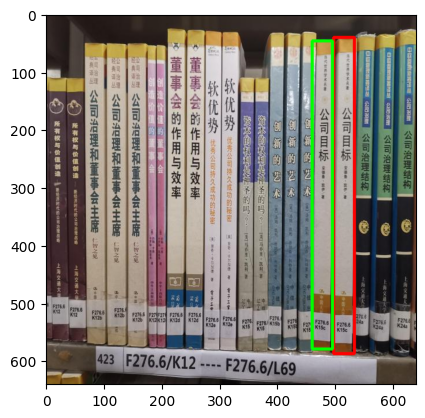

{'book_19-scene_7': {'detections': 2,
  'corners': [array([[497,  40],
          [533,  40],
          [533, 587],
          [497, 587]], dtype=int32),
   array([[460,  46],
          [495,  46],
          [495, 579],
          [460, 579]]),
   array([[ 58,  46],
          [ 92,  45],
          [110, 565],
          [ 76, 566]]),
   array([[239,  36],
          [274,  36],
          [274, 569],
          [239, 569]]),
   array([[ 95,  49],
          [129,  48],
          [147, 568],
          [113, 569]]),
   array([[131,  49],
          [165,  48],
          [183, 567],
          [149, 569]]),
   array([[206,  39],
          [241,  39],
          [241, 572],
          [206, 572]]),
   array([[278,  41],
          [316,  39],
          [336, 613],
          [298, 614]]),
   array([[380,  28],
          [414,  30],
          [378, 549],
          [344, 547]]),
   array([[173,  50],
          [207,  50],
          [207, 570],
          [173, 570]]),
   array([[339,  91],
          [373, 

In [18]:
lowe_ratio = 0.75
min_match_pct = 0.125
hyst_th = (0.034, 0.26)
FLANN = False
sift_params = (0.025, 4, 1.03, 7, 0)  # contrast_threshold, edge_threshold, sigma, nOctaveLayers, nfeatures
# 19-7
# 15-11
# 16-11
# 27-2
# 7-20
# 9-19
scene_path = f'./dataset/scenes/scene_19.jpg'
model_path = f'./dataset/models/model_7.png'

main(model_path, scene_path,
    sift_params=sift_params, 
    hysteresys_th=hyst_th, 
    min_match_pct=min_match_pct,
    lowe_ratio=lowe_ratio, 
    ransacReprojThreshold=5.0, 
    book_idx=19,
    scene_idx=7,
    results_dict={},
    FLANN=FLANN,
    visualize=True)

### Repeat the process over all the possible model-scene pairs

In [ ]:
lowe_ratio = 0.75
# min_match_pct = 0.125
min_match_pct = 0.135
hyst_th = (0.034, 0.3) 
sift_params = (0.025, 4, 1.03, 7, 0)  # contrast_threshold, edge_threshold, sigma, nOctaveLayers, nfeatures

results = {}

for i in range(0, 29):
     print(f"--------------------------------- Processing scene {i} ---------------------------------")
     scene_path = f'./dataset/scenes/scene_{i}.jpg'
     for j in range(0, 22):
          print(f"\n -------- Processing model {j} --------")

          model_path = f'./dataset/models/model_{j}.png'
          
          results = main(model_path, scene_path, 
               sift_params=sift_params,
               hysteresys_th=hyst_th, 
               min_match_pct=min_match_pct,
               lowe_ratio=lowe_ratio, 
               ransacReprojThreshold=5.0, 
               book_idx=j,
               scene_idx=i,
               results_dict=results,
               visualize=True)
          
          detections = results[f"book_{j}-scene_{i}"]['detections']
          if detections > 0:
               print(f"Book {j} - {detections} instance(s) found:")
               for k in range(detections):
                    corners = results[f"book_{j}-scene_{i}"]['corners'][k]
                    
                    area = results[f"book_{j}-scene_{i}"]['area'][k]

                    top_left     = tuple(map(int, corners[0].ravel()))
                    top_right    = tuple(map(int, corners[3].ravel()))
                    bottom_left  = tuple(map(int, corners[1].ravel()))
                    bottom_right = tuple(map(int, corners[2].ravel()))

                    print(f"\t Instance {k+1}: {{top-left: {top_left}, top-right: {top_right}, bottom-left: {bottom_left}, bottom-right: {bottom_right}, area: {int(area)}px}}")
          else:
               print(f"Book {j} - {detections} instance(s) found")

--------------------------------- Processing scene 0 ---------------------------------

 -------- Processing model 0 --------
Book 0 - 0 instance(s) found

 -------- Processing model 1 --------
Book 1 - 0 instance(s) found

 -------- Processing model 2 --------
Book 2 - 0 instance(s) found

 -------- Processing model 3 --------
Book 3 - 0 instance(s) found

 -------- Processing model 4 --------
Book 4 - 0 instance(s) found

 -------- Processing model 5 --------
Book 5 - 0 instance(s) found

 -------- Processing model 6 --------
Book 6 - 0 instance(s) found

 -------- Processing model 7 --------
Book 7 - 0 instance(s) found

 -------- Processing model 8 --------
Book 8 - 0 instance(s) found

 -------- Processing model 9 --------
Book 9 - 0 instance(s) found

 -------- Processing model 10 --------
Book 10 - 0 instance(s) found

 -------- Processing model 11 --------
Book 11 - 0 instance(s) found

 -------- Processing model 12 --------
Book 12 - 0 instance(s) found

 -------- Processing m

### **Limitations**

- **Dependence on the First Instance**: The entire pipeline relies on the successful detection of the first instance using SIFT and homography. If the algorithm fails to detect the first occurrence of a book, subsequent occurrences will never be found. Similarly, if the first instance is partially occluded, the algorithm expects the same occlusion in all others, which is not a too realistic assumption.

- **Limited Robustness to Scale and Rotation Variations**: The method assumes that all book instances appear with similar scale and orientation. While small transformations are handled through rotated and rescaled template matching, larger variations can significantly reduce detection accuracy. Although it is possible to extend our approach to a wider range of angles and scales, doing so would significantly increase computational complexity.

- **Scalability Constraints**: As the number of model-scene combinations or the size of the input increase, the computational cost grows quickly due to repeated SIFT matching, homography estimation, and especially iterative template matching.

- **Masking**: Masking already processed regions with a black patch helps avoid redundant attempts on the same areas. However, this technique can negatively affect subsequent detections in nearby windows, especially in scenes with closely spaced objects or the model book is almost full black. To mitigate this issue, we apply a shrink to the black patch along the longer side of the book.
